# Part 6 Product Performance and Operational Decision Support


In this part, I focused on understanding which products contribute the most to Melt Gelato's sales and how this information could support inventory decisions.

I used the cleaned sales dataset from the earlier analysis, keeping completed payments separate from refunds and voided transactions.

The aim was to identify important products, examine commonly purchased combinations, and understand which categories experience greater changes in daily demand.

## 6.1 Setup and load the validated sales data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
PROCESSED_DIR = ROOT / "data" / "processed"
INPUT = PROCESSED_DIR / "cleaned_sales.csv"
assert INPUT.exists(), f"Missing {INPUT.resolve()}. Run notebook 02 first."
df = pd.read_csv(INPUT, parse_dates=["sale_date"], low_memory=False)
required = {"Transaction ID", "Item", "Qty", "Gross Sales_eur", "sale_date", "is_payment", "is_refund", "is_void"}
missing = required - set(df.columns)
assert not missing, f"Missing columns: {sorted(missing)}"
for col in ["is_payment", "is_refund", "is_void"]:
    df[col] = df[col].astype(str).str.strip().str.lower().map({"true": True, "false": False, "1": True, "0": False})
    assert df[col].notna().all(), f"Unexpected values in {col}"
for col in ["Gross Sales_eur", "Qty"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
df["item_clean"] = df["Item"].astype("string").str.strip()
df["item_clean"] = df["item_clean"].replace("", pd.NA)
df["category_clean"] = df.get("category_analysis", df.get("Category", pd.Series(index=df.index, dtype="string"))).astype("string").str.strip().fillna("Uncategorised")
df.loc[df["category_clean"].eq(""), "category_clean"] = "Uncategorised"
payments = df.loc[df["is_payment"] & ~df["is_void"]].copy()
refunds = df.loc[df["is_refund"] & ~df["is_void"]].copy()
print(f"All cleaned lines: {len(df):,}; payment lines: {len(payments):,}; refund lines: {len(refunds):,}")
print(f"Payment gross: €{payments['Gross Sales_eur'].sum():,.2f}; refund-adjusted gross: €{(payments['Gross Sales_eur'].sum()+refunds['Gross Sales_eur'].sum()):,.2f}")
print("Missing item labels on payment lines:", payments["item_clean"].isna().sum())

All cleaned lines: 122,419; payment lines: 106,156; refund lines: 844
Payment gross: €548,244.35; refund-adjusted gross: €542,676.35
Missing item labels on payment lines: 0


### Understanding Product Performance

I started by comparing products based on their total revenue and quantities sold.

I wanted to understand whether the products selling the most units were also generating the highest revenue.

The results showed that Gelato was the highest-revenue product, followed by Vanilla Milkshake and Cappuccino.

However, products with high sales volumes did not always generate equally high revenue. This distinction is useful when deciding which products should receive greater attention in inventory planning.

## 6.2 Product revenue and volume ranking

Top 15 products by gross payment revenue:


,item_clean,payment_gross_eur,units_sold,line_count,trading_days,payment_revenue_share_pct
0,Gelato,120501.8,25664.0,19202,360,21.98
1,Vanilla Milkshake,41544.0,7055.0,5790,360,7.58
2,Cappuccino,31327.2,8838.0,7543,360,5.71
3,Melted tub,17894.5,3293.0,2613,352,3.26
4,Bueno Buster Tub,15446.0,2397.0,2090,350,2.82
5,99 Cones,14944.6,5671.0,4558,351,2.73
6,Americano,13235.7,4062.0,3518,360,2.41
7,Strawberry & Nutella crepe,12675.0,1950.0,1664,345,2.31
8,Nutella Crepe,11377.5,1896.0,1624,351,2.08
9,White Kinder Tub,10142.0,1565.0,1425,317,1.85


Top 15 products by units sold:


,item_clean,payment_gross_eur,units_sold,line_count,trading_days,payment_revenue_share_pct
0,Gelato,120501.8,25664.0,19202,360,21.98
12,Topping,8905.5,17230.0,8778,360,1.62
2,Cappuccino,31327.2,8838.0,7543,360,5.71
1,Vanilla Milkshake,41544.0,7055.0,5790,360,7.58
5,99 Cones,14944.6,5671.0,4558,351,2.73
6,Americano,13235.7,4062.0,3518,360,2.41
3,Melted tub,17894.5,3293.0,2613,352,3.26
4,Bueno Buster Tub,15446.0,2397.0,2090,350,2.82
15,Latte,8066.4,2279.0,2027,349,1.47
68,Hot sauce,1372.0,1960.0,1673,338,0.25


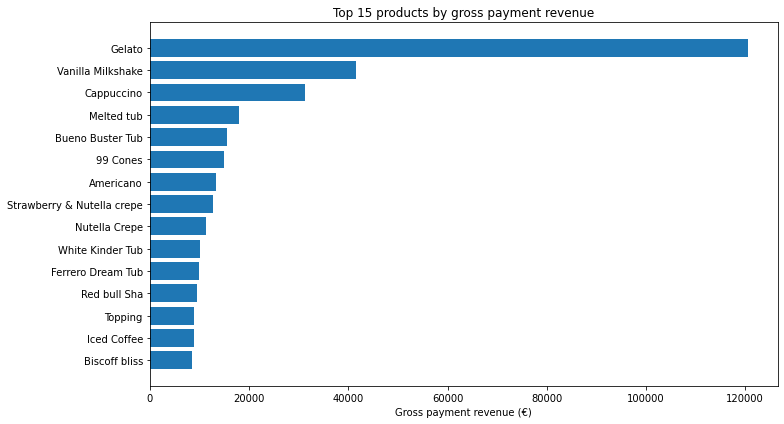

In [2]:
product_lines = payments.loc[payments["item_clean"].notna()].copy()
product_summary = (product_lines.groupby("item_clean", as_index=False)
    .agg(payment_gross_eur=("Gross Sales_eur", "sum"), units_sold=("Qty", "sum"),
         line_count=("Item", "size"), trading_days=("sale_date", "nunique")))
product_summary = product_summary.sort_values("payment_gross_eur", ascending=False).reset_index(drop=True)
product_summary["payment_revenue_share_pct"] = 100 * product_summary["payment_gross_eur"] / product_summary["payment_gross_eur"].sum()
print("Top 15 products by gross payment revenue:")
display(product_summary.head(15).round(2))
print("Top 15 products by units sold:")
display(product_summary.sort_values("units_sold", ascending=False).head(15).round(2))
fig, ax = plt.subplots(figsize=(11, 6))
top = product_summary.head(15).iloc[::-1]
ax.barh(top["item_clean"].astype(str), top["payment_gross_eur"])
ax.set(xlabel="Gross payment revenue (€)", title="Top 15 products by gross payment revenue")
plt.tight_layout(); plt.show()

### ABC Classification

Next, I used ABC classification to understand how revenue was distributed across different products.

I ranked products by payment revenue and calculated their cumulative contribution to total sales.

The results showed that 44 Category A products generated 80.45% of payment revenue, while 61 Category B products contributed 14.58%. The remaining 282 Category C products contributed 4.97%.

I also created a Pareto curve to visualise this distribution.

These findings suggest that a relatively small group of products accounts for most of the business's revenue. Monitoring the availability of these products could therefore be particularly useful for inventory planning.

## 6.3 ABC classification and Pareto concentration

,abc_class,products,payment_revenue_eur,revenue_share_pct,product_share_pct
0,A,44,441076.70,80.45,11.37
1,B,61,79933.70,14.58,15.76
2,C,282,27233.95,4.97,72.87


Highest revenue A-class items:


,item_clean,payment_gross_eur,cumulative_revenue_pct,abc_class
0,Gelato,120501.8,21.98,A
1,Vanilla Milkshake,41544.0,29.56,A
2,Cappuccino,31327.2,35.27,A
3,Melted tub,17894.5,38.54,A
4,Bueno Buster Tub,15446.0,41.35,A
5,99 Cones,14944.6,44.08,A
6,Americano,13235.7,46.49,A
7,Strawberry & Nutella crepe,12675.0,48.80,A
8,Nutella Crepe,11377.5,50.88,A
9,White Kinder Tub,10142.0,52.73,A


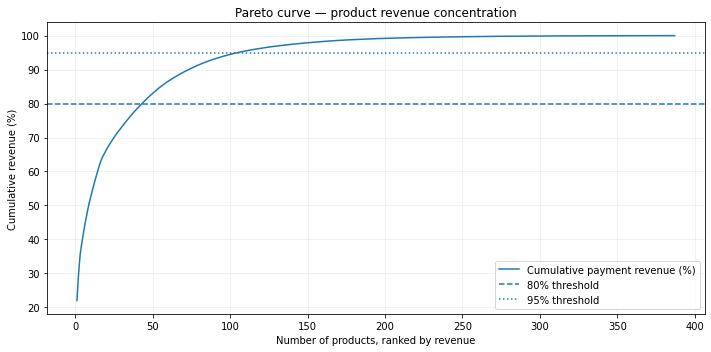

In [ ]:
# ABC thresholds are a transparent convention, not a universal inventory rule.
# Products crossing a boundary are assigned according to cumulative share BEFORE that product.

abc = product_summary.loc[product_summary["payment_gross_eur"] > 0].copy()
abc = abc.sort_values("payment_gross_eur", ascending=False).reset_index(drop=True)
total = abc["payment_gross_eur"].sum()
abc["revenue_share_pct"] = 100 * abc["payment_gross_eur"] / total
abc["cumulative_revenue_pct"] = abc["revenue_share_pct"].cumsum()
abc["cumulative_before_pct"] = abc["cumulative_revenue_pct"] - abc["revenue_share_pct"]
abc["abc_class"] = np.select([abc["cumulative_before_pct"] < 80, abc["cumulative_before_pct"] < 95], ["A", "B"], default="C")
abc_summary = (abc.groupby("abc_class", as_index=False)
    .agg(products=("item_clean", "size"), payment_revenue_eur=("payment_gross_eur", "sum")))
abc_summary["revenue_share_pct"] = 100 * abc_summary["payment_revenue_eur"] / total
abc_summary["product_share_pct"] = 100 * abc_summary["products"] / len(abc)
display(abc_summary.round(2))
print("Highest revenue A-class items:")
display(abc.loc[abc["abc_class"].eq("A")].head(15)[["item_clean", "payment_gross_eur", "cumulative_revenue_pct", "abc_class"]].round(2))
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, len(abc)+1)
ax.plot(x, abc["cumulative_revenue_pct"], label="Cumulative payment revenue (%)")
ax.axhline(80, linestyle="--", label="80% threshold")
ax.axhline(95, linestyle=":", label="95% threshold")
ax.set(xlabel="Number of products, ranked by revenue", ylabel="Cumulative revenue (%)", title="Pareto curve — product revenue concentration")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

## 6.4 Product combinations within transactions

I also wanted to understand which products customers commonly purchased together.


Unlike a daily product-sales correlation, **basket analysis** asks whether two named items occur in the *same transaction*. The unit of analysis is a distinct `Transaction ID` (not a POS line). We deduplicate repeated item labels within each transaction and exclude blank IDs and item names. A basket containing one product cannot produce a pair.

Metrics: **support** = share of all baskets containing both items; **confidence(A→B)** = share of baskets containing A that also contain B; **lift** = confidence(A→B) / share of baskets containing B. Lift above 1 is association, **not causation**.

These findings could help the business explore potential combination offers, although the results do not guarantee that promotions would increase sales.

In [4]:
from collections import Counter
from itertools import combinations

basket_lines = payments.loc[payments["Transaction ID"].notna() & payments["item_clean"].notna(), ["Transaction ID", "item_clean"]].drop_duplicates()
baskets = basket_lines.groupby("Transaction ID")["item_clean"].agg(lambda s: sorted(set(s.astype(str))))
N = len(baskets)
item_counts = Counter(item for basket in baskets for item in basket)
print(f"Baskets: {N:,}; baskets with 2+ distinct items: {(baskets.map(len)>=2).sum():,}")
# Focus on frequent products to avoid noisy combinations and excessive pair counts.
MIN_ITEM_BASKETS = max(20, int(np.ceil(N * .005)))
frequent = {item for item, count in item_counts.items() if count >= MIN_ITEM_BASKETS}
pair_counts = Counter()
for basket in baskets:
    chosen = sorted(set(basket).intersection(frequent))
    pair_counts.update(combinations(chosen, 2))
rows = []
for (a, b), both in pair_counts.items():
    if both < 20: continue
    support = both / N
    for antecedent, consequent in [(a, b), (b, a)]:
        confidence = both / item_counts[antecedent]
        consequent_share = item_counts[consequent] / N
        rows.append({"antecedent": antecedent, "consequent": consequent,
                     "baskets_together": both, "support_pct": support*100,
                     "confidence_pct": confidence*100,
                     "lift": confidence / consequent_share})
rules = pd.DataFrame(rows, columns=["antecedent", "consequent", "baskets_together", "support_pct", "confidence_pct", "lift"])
if rules.empty:
    print("No product pairs passed the minimum basket thresholds. Consider revising thresholds transparently.")
else:
    rules = rules.sort_values(["lift", "baskets_together"], ascending=False)
    print("Top candidate associations (minimum 20 joint baskets):")
    display(rules.head(20).round(3))

Baskets: 58,891; baskets with 2+ distinct items: 28,486
Top candidate associations (minimum 20 joint baskets):


,antecedent,consequent,baskets_together,support_pct,confidence_pct,lift
92,Iced Coffee,Syrup,209,0.355,13.194,19.975
93,Syrup,Iced Coffee,209,0.355,53.728,19.975
228,Black pudding sausage roll,Coffee - Tea,60,0.102,6.529,12.606
229,Coffee - Tea,Black pudding sausage roll,60,0.102,19.672,12.606
445,Scone,Coffee - Tea,39,0.066,6.260,12.087
444,Coffee - Tea,Scone,39,0.066,12.787,12.087
410,Strawberries,White kinder waffle,37,0.063,6.537,11.809
411,White kinder waffle,Strawberries,37,0.063,11.350,11.809
273,Tea,Ham and Cheese,44,0.075,5.251,10.105
272,Ham and Cheese,Tea,44,0.075,14.379,10.105


### Comparing Demand Variability Across Categories

After identifying the highest-revenue products, I examined how consistently different product categories generated revenue throughout the year.

I calculated average daily revenue, standard deviation, and the coefficient of variation for the leading categories.

The results showed that Gelato had a coefficient of variation of 0.69, compared with 0.25 for Coffee.

This suggests that Gelato revenue fluctuated more relative to its average, while Coffee revenue was comparatively stable.

Understanding these differences could help Melt Gelato adjust preparation and inventory monitoring according to the demand patterns of individual categories.

## 6.5 Daily category demand variability

,mean_daily_revenue_eur,std_daily_revenue_eur,zero_revenue_observed_days,cv
category_clean,,,,
Gelato,400.07,275.50,0,0.69
Coffee,273.07,68.04,0,0.25
Special Tubs,247.97,165.23,0,0.67
Waffles and Crepes,205.35,88.05,0,0.43
Milkshakes,127.92,69.92,0,0.55
Menu,44.96,29.72,24,0.66
Uncategorised,44.79,62.59,46,1.40
Grilled Sandwiches,33.96,23.71,19,0.70
Toppings,30.03,23.32,0,0.78


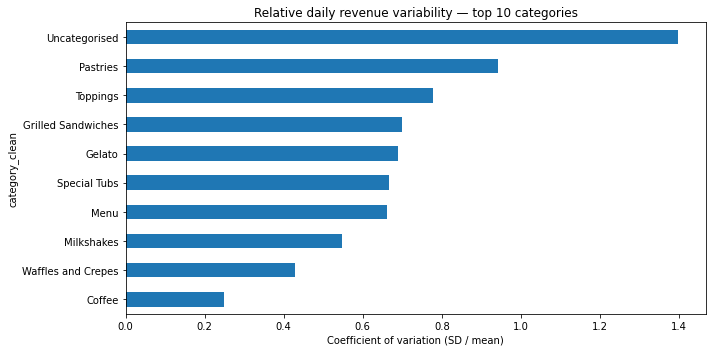

In [5]:
category_daily = (product_lines.groupby(["sale_date", "category_clean"], as_index=False)
    .agg(payment_gross_eur=("Gross Sales_eur", "sum"), units=("Qty", "sum")))
observed_dates = pd.DatetimeIndex(sorted(payments["sale_date"].dropna().unique()))
cat_totals = category_daily.groupby("category_clean")["payment_gross_eur"].sum().sort_values(ascending=False)
selected_categories = cat_totals.head(10).index
wide = (category_daily.loc[category_daily["category_clean"].isin(selected_categories)]
        .pivot(index="sale_date", columns="category_clean", values="payment_gross_eur")
        .reindex(observed_dates).fillna(0))
# 0 means no revenue for that category on a date with other observed POS sales.
# Entirely missing POS dates are NOT treated as confirmed zero-revenue days.
variability = pd.DataFrame({"mean_daily_revenue_eur": wide.mean(),
                            "std_daily_revenue_eur": wide.std(),
                            "zero_revenue_observed_days": (wide == 0).sum()})
variability["cv"] = np.where(variability["mean_daily_revenue_eur"] > 0,
                             variability["std_daily_revenue_eur"] / variability["mean_daily_revenue_eur"], np.nan)
display(variability.sort_values("mean_daily_revenue_eur", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(10, 5))
variability.sort_values("cv")["cv"].plot.barh(ax=ax)
ax.set(xlabel="Coefficient of variation (SD / mean)", title="Relative daily revenue variability — top 10 categories")
plt.tight_layout(); plt.show()

### Checking and Saving the Results

Before completing the analysis, I checked that the calculated revenue totals were consistent with the cleaned sales data.

I also saved the product rankings, ABC classification results, market basket associations, and category variability summaries as separate CSV files.

These outputs can be reused for reporting, visualisation, and further analysis without repeating the calculations.

## 6.6 Quality checks and reusable outputs

In [6]:
assert np.isclose(payments["Gross Sales_eur"].sum() + refunds["Gross Sales_eur"].sum(),
                  df.loc[(df["is_payment"] | df["is_refund"]) & ~df["is_void"], "Gross Sales_eur"].sum())
assert np.isclose(product_summary["payment_gross_eur"].sum(), product_lines["Gross Sales_eur"].sum())
assert np.isclose(abc["payment_gross_eur"].sum(), abc_summary["payment_revenue_eur"].sum())
print("Reconciliation checks passed.")
print("Payment revenue excluded from named-product analysis (missing item names): €",
      round(payments["Gross Sales_eur"].sum() - product_lines["Gross Sales_eur"].sum(), 2))
product_summary.to_csv(PROCESSED_DIR / "product_performance.csv", index=False)
abc.to_csv(PROCESSED_DIR / "product_abc_classification.csv", index=False)
abc_summary.to_csv(PROCESSED_DIR / "product_abc_summary.csv", index=False)
rules.to_csv(PROCESSED_DIR / "product_basket_rules.csv", index=False)
variability.to_csv(PROCESSED_DIR / "category_demand_variability.csv")
print("Saved 5 Part 6 outputs to:", PROCESSED_DIR.resolve())

Reconciliation checks passed.
Payment revenue excluded from named-product analysis (missing item names): € 0.0
Saved 5 Part 6 outputs to: /Users/aakritiabhaysingh/Desktop/melt final/data/processed


## 6.7 Interpretation notes
**Reconciliation.** The dataset contained **106,156 non-void payment lines** and **844 non-void refund lines**. Payment-only gross revenue was **€548,244.35**, and refund-adjusted gross revenue was **€542,676.35**. Product rankings and ABC classes use **payment-only gross revenue**, not profit or refund-adjusted product revenue. No payment revenue was excluded due to missing item names.

**Product performance.** Gelato was the leading named product with **€120,501.80** and **25,664 units**, followed by Vanilla Milkshake (**€41,544.00**) and Cappuccino (**€31,327.20**) by revenue. Topping sold **17,230 units** but generated **€8,905.50**, illustrating that high unit sales do not always mean high revenue.

**ABC analysis.** Of **387 positive-revenue product labels**, **44 A-class labels (11.37%)** generated **€441,076.70 (80.45%)** of payment revenue. **61 B-class labels (15.76%)** contributed **€79,933.70 (14.58%)**; **282 C-class labels (72.87%)** contributed **€27,233.95 (4.97%)**. Revenue is concentrated among relatively few labels. This supports prioritising availability reviews, but does not establish profitability or optimal stock quantities.

**Basket analysis.** There were **58,891 payment transaction baskets**, with **28,486** containing at least two distinct labels. Example pairs include Iced Coffee–Syrup (**209** shared baskets), Black pudding sausage roll–Coffee - Tea (**60**), and Scone–Coffee - Tea (**39**). These may be modifiers or habitual combinations; co-occurrence does not prove promotional uplift.

**Variability.** Gelato averaged **€400.07** in payment revenue per recorded day (CV **0.69**), compared with Coffee at **€273.07** (CV **0.25**). Special Tubs had CV approximately **0.60**. Gelato revenue was therefore more variable relative to its mean. Variability is not a direct measure of food waste.

**Business implication.** Monitor availability of high-revenue products, review preparation for volatile categories, and consider testing frequently observed combinations. Without margins, purchase costs, stock counts and wastage records, precise inventory recommendations or savings cannot be justified.